In [1]:
from google.colab import files
import zipfile
import io
import os

uploaded = files.upload()

zip_name = next(iter(uploaded))

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), "r") as z:
    z.extractall("/content/marketing_data")

print("ZIP file extracted successfully!")

print(os.listdir("/content/marketing_data"))

Saving bank+marketing (2).zip to bank+marketing (2) (1).zip
ZIP file extracted successfully!
['bank-additional.zip', 'bank.zip']


In [2]:
import zipfile
import os

folder = "/content/marketing_data"

for filename in ["bank.zip", "bank-additional.zip"]:
    path = os.path.join(folder, filename)

    with zipfile.ZipFile(path, "r") as z:
        z.extractall(folder)

print("Inner ZIP files extracted successfully!")
print(os.listdir(folder))


Inner ZIP files extracted successfully!
['bank-full.csv', 'bank.csv', 'bank-additional.zip', 'bank.zip', '__MACOSX', 'bank-additional', 'bank-names.txt']


In [3]:
import pandas as pd

file_path = "/content/marketing_data/bank-full.csv"

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())




Dataset loaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:

import pandas as pd

file_path = "/content/marketing_data/bank-full.csv"

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())



Dataset loaded successfully!
Number of rows and columns: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nConversion Results:")
print(df["y"].value_counts())


Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 n

In [6]:

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFinal dataset shape:", df.shape)
print("Data cleaning completed!")


Duplicate rows: 0

Missing values:
0

Final dataset shape: (45211, 17)
Data cleaning completed!


In [7]:

total_contacts = len(df)

conversions = (df["y"] == "yes").sum()
non_conversions = (df["y"] == "no").sum()

conversion_rate = (conversions / total_contacts) * 100
non_conversion_rate = (non_conversions / total_contacts) * 100

print("Total Campaign Contacts:", total_contacts)
print("Successful Conversions:", conversions)
print("Unsuccessful Conversions:", non_conversions)
print(f"Conversion Rate: {conversion_rate:.2f}%")
print(f"Non-Conversion Rate: {non_conversion_rate:.2f}%")


Total Campaign Contacts: 45211
Successful Conversions: 5289
Unsuccessful Conversions: 39922
Conversion Rate: 11.70%
Non-Conversion Rate: 88.30%


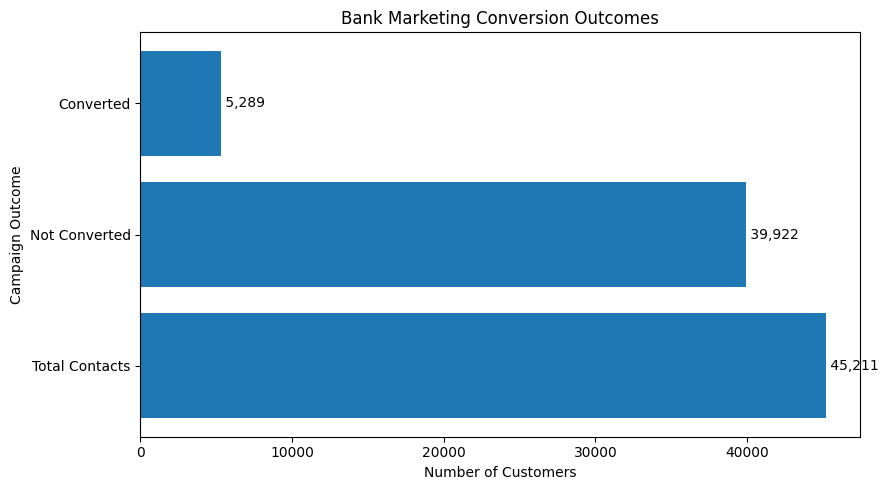

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

stages = ["Total Contacts", "Not Converted", "Converted"]
values = [total_contacts, non_conversions, conversions]

plt.figure(figsize=(9, 5))
bars = plt.barh(stages, values)

plt.title("Bank Marketing Conversion Outcomes")
plt.xlabel("Number of Customers")
plt.ylabel("Campaign Outcome")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {value:,}",
        va="center"
    )

plt.tight_layout()
plt.show()


In [9]:

channel_analysis = df.groupby("contact").agg(
    Total_Contacts=("y", "size"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

channel_analysis["Conversion_Rate_%"] = (
    channel_analysis["Conversions"]
    / channel_analysis["Total_Contacts"] * 100
)

channel_analysis = channel_analysis.sort_values(
    "Conversion_Rate_%", ascending=False
)

display(channel_analysis.round(2))


,Total_Contacts,Conversions,Conversion_Rate_%
contact,,,
cellular,29285,4369,14.92
telephone,2906,390,13.42
unknown,13020,530,4.07


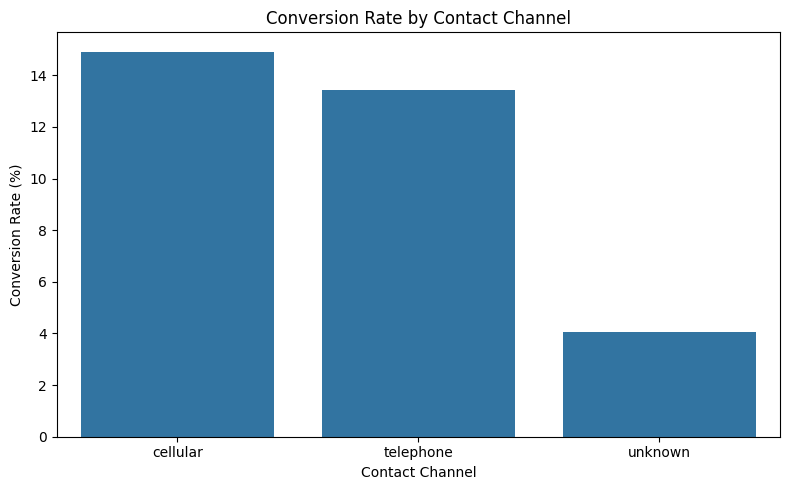

In [10]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=channel_analysis.reset_index(),
    x="contact",
    y="Conversion_Rate_%"
)

plt.title("Conversion Rate by Contact Channel")
plt.xlabel("Contact Channel")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()


In [11]:

campaign_analysis = df.groupby("campaign").agg(
    Total_Contacts=("y", "size"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

campaign_analysis["Conversion_Rate_%"] = (
    campaign_analysis["Conversions"]
    / campaign_analysis["Total_Contacts"] * 100
)

display(campaign_analysis.head(15).round(2))


,Total_Contacts,Conversions,Conversion_Rate_%
campaign,,,
1,17544,2561,14.60
2,12505,1401,11.20
3,5521,618,11.19
4,3522,317,9.00
5,1764,139,7.88
6,1291,92,7.13
7,735,47,6.39
8,540,32,5.93
9,327,21,6.42


In [12]:

monthly_analysis = df.groupby("month").agg(
    Total_Contacts=("y", "size"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

monthly_analysis["Conversion_Rate_%"] = (
    monthly_analysis["Conversions"]
    / monthly_analysis["Total_Contacts"] * 100
)

display(
    monthly_analysis.sort_values(
        "Conversion_Rate_%", ascending=False
    ).round(2)
)


,Total_Contacts,Conversions,Conversion_Rate_%
month,,,
mar,477,248,51.99
dec,214,100,46.73
sep,579,269,46.46
oct,738,323,43.77
apr,2932,577,19.68
feb,2649,441,16.65
aug,6247,688,11.01
jun,5341,546,10.22
nov,3970,403,10.15


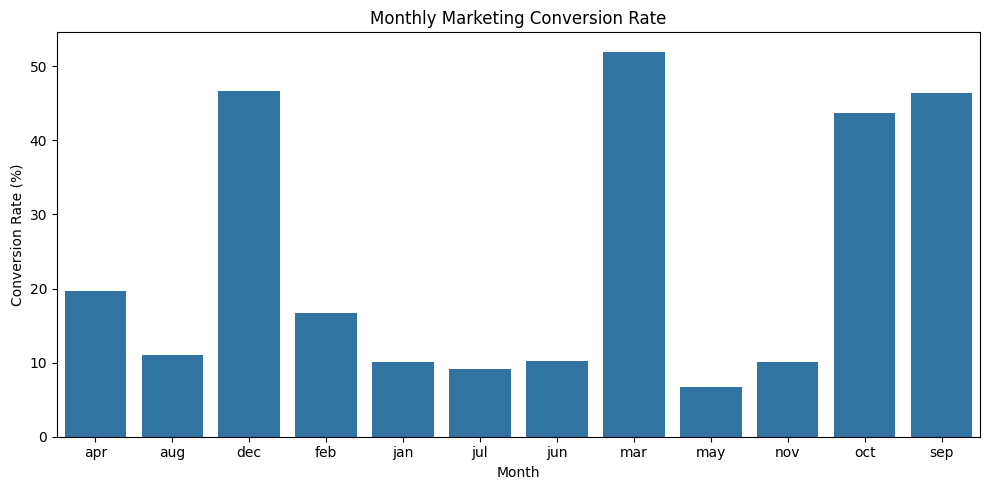

In [13]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_analysis.index,
    y=monthly_analysis["Conversion_Rate_%"]
)

plt.title("Monthly Marketing Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()


In [14]:

previous_analysis = df.groupby("poutcome").agg(
    Total_Contacts=("y", "size"),
    Conversions=("y", lambda x: (x == "yes").sum())
)

previous_analysis["Conversion_Rate_%"] = (
    previous_analysis["Conversions"]
    / previous_analysis["Total_Contacts"] * 100
)

display(previous_analysis.round(2))


,Total_Contacts,Conversions,Conversion_Rate_%
poutcome,,,
failure,4901,618,12.61
other,1840,307,16.68
success,1511,978,64.73
unknown,36959,3386,9.16


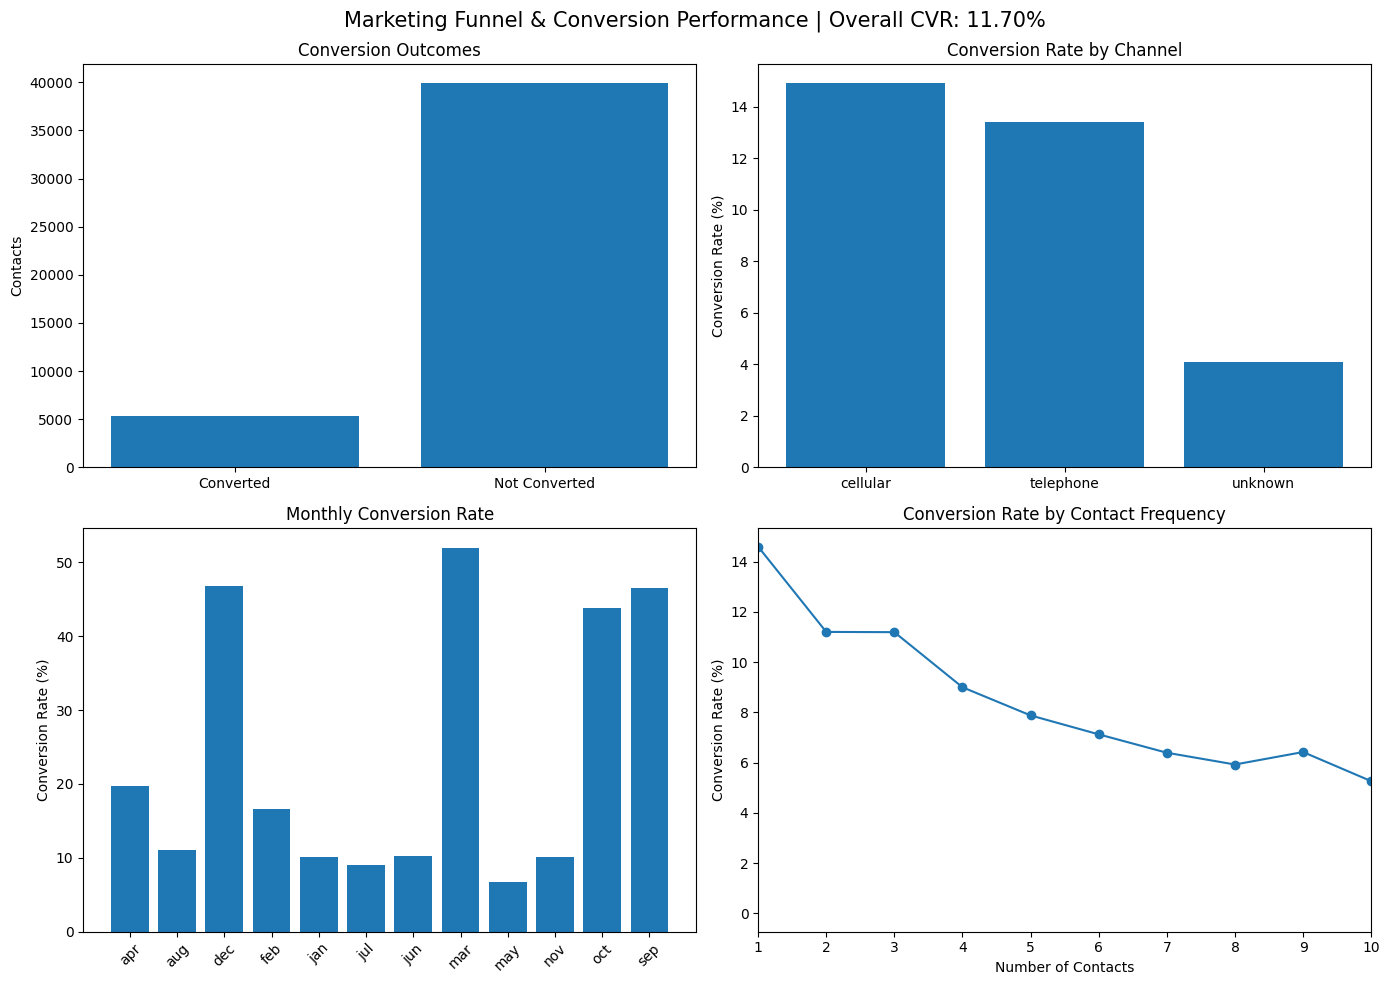

In [15]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# KPI 1: Conversion outcome
axes[0, 0].bar(
    ["Converted", "Not Converted"],
    [conversions, non_conversions]
)
axes[0, 0].set_title("Conversion Outcomes")
axes[0, 0].set_ylabel("Contacts")

# KPI 2: Channel conversion rates
axes[0, 1].bar(
    channel_analysis.index,
    channel_analysis["Conversion_Rate_%"]
)
axes[0, 1].set_title("Conversion Rate by Channel")
axes[0, 1].set_ylabel("Conversion Rate (%)")

# KPI 3: Monthly conversion rates
axes[1, 0].bar(
    monthly_analysis.index,
    monthly_analysis["Conversion_Rate_%"]
)
axes[1, 0].set_title("Monthly Conversion Rate")
axes[1, 0].set_ylabel("Conversion Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=45)

# KPI 4: Campaign contact frequency
axes[1, 1].plot(
    campaign_analysis.index,
    campaign_analysis["Conversion_Rate_%"],
    marker="o"
)
axes[1, 1].set_title("Conversion Rate by Contact Frequency")
axes[1, 1].set_xlabel("Number of Contacts")
axes[1, 1].set_ylabel("Conversion Rate (%)")
axes[1, 1].set_xlim(1, 10)

fig.suptitle(
    f"Marketing Funnel & Conversion Performance | Overall CVR: {conversion_rate:.2f}%",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [17]:

best_channel = channel_analysis["Conversion_Rate_%"].idxmax()
best_channel_rate = channel_analysis["Conversion_Rate_%"].max()

best_month = monthly_analysis["Conversion_Rate_%"].idxmax()
best_month_rate = monthly_analysis["Conversion_Rate_%"].max()

print("MARKETING PERFORMANCE REPORT")
print("-" * 35)

print(f"Total contacts: {total_contacts:,}")
print(f"Conversions: {conversions:,}")
print(f"Overall conversion rate: {conversion_rate:.2f}%")
print(f"Non-conversion rate: {non_conversion_rate:.2f}%")

print(
    f"\nHighest observed channel conversion: "
    f"{best_channel} ({best_channel_rate:.2f}%)"
)

print(
    f"Highest observed monthly conversion: "
    f"{best_month} ({best_month_rate:.2f}%)"
)


MARKETING PERFORMANCE REPORT
-----------------------------------
Total contacts: 45,211
Conversions: 5,289
Overall conversion rate: 11.70%
Non-conversion rate: 88.30%

Highest observed channel conversion: cellular (14.92%)
Highest observed monthly conversion: mar (51.99%)


In [18]:

df.to_csv("cleaned_bank_marketing.csv", index=False)

channel_analysis.to_csv("channel_conversion_analysis.csv")
monthly_analysis.to_csv("monthly_conversion_analysis.csv")
campaign_analysis.to_csv("campaign_conversion_analysis.csv")

print("All analysis files saved successfully!")


All analysis files saved successfully!


In [19]:

from google.colab import files

files.download("cleaned_bank_marketing.csv")
files.download("channel_conversion_analysis.csv")
files.download("monthly_conversion_analysis.csv")
files.download("campaign_conversion_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>